In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.base import clone 
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from project_ml.Cleaning import clean_data_iqr

In [3]:
df_all = fetch_california_housing(as_frame=True).frame
df_clean = clean_data_iqr(df_all)
print(len(df_all), "->", len(df_clean))

X = df_clean.drop(columns="MedHouseVal").values
y = df_clean["MedHouseVal"].values

X_rest, X_test, y_rest, y_test = train_test_split(X, y,test_size=0.2, random_state=123)
print(X_rest.shape, X_test.shape)

20640 -> 19263
(15410, 8) (3853, 8)


In [4]:
param_grid = {"max_depth" : [None, 10, 20],
              "min_samples_leaf" : [1, 5, 10],
              "max_features" : [1.0, "sqrt"]}

rf = RandomForestRegressor(n_estimators= 100, random_state=0, n_jobs=-1)
grid_search = GridSearchCV(rf, param_grid, scoring= "neg_mean_squared_error", cv=3)
grid_search.fit(X_rest,y_rest)
print(grid_search.best_params_)

{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1}


No max depth, max features = sqrt and min leaf = 1 district in the last leaf !

In [5]:
models = {
    "Linear Regression" : LinearRegression(),
    "Random Forest" : RandomForestRegressor(**grid_search.best_params_, n_estimators= 100, random_state=0, n_jobs=-1),
}

perf = []
for name, model in models.items() :
    y_pred = clone(model).fit(X_rest,y_rest).predict(X_test)
    perf.append({"Model" : name,
                 "RMSE" : np.sqrt(mean_squared_error(y_test, y_pred)),
                 "MSE" : mean_squared_error(y_test, y_pred),
                 "R2" : r2_score(y_test, y_pred)})
pd.DataFrame(perf).round(4)


,Model,RMSE,MSE,R2
0,Linear Regression,0.6362,0.4048,0.6882
1,Random Forest,0.4753,0.2259,0.8260


The result is expected, the Random forest is largely better than the linear Regression with a lower MSE, RMSE and a higher R2 for RF.

Wa Start By the CV + methode !

In [6]:
def plus_bounds(preds, residuals, alpha):
    n = len(residuals)
    k_lo = int(np.floor(alpha * (n + 1)))
    k_up = int(np.ceil((1 - alpha) * (n + 1)))
    low = np.partition(preds - residuals[:, None], k_lo - 1, axis=0)[k_lo - 1]
    up = np.partition(preds + residuals[:, None], k_up - 1, axis=0)[k_up - 1]
    return low, up

def cv_plus(model, X, y, X_test, alpha=0.10, K=10, chunk=1000):
    n = len(y)
    fold_of = np.empty(n, dtype=int)
    residuals = np.empty(n)
    test_preds = np.empty((K, len(X_test)))
    for k, (tr, va) in enumerate(KFold(K, shuffle=True, random_state=0).split(X)):
        m = clone(model).fit(X[tr], y[tr])
        fold_of[va] = k
        residuals[va] = np.abs(y[va] - m.predict(X[va]))
        test_preds[k] = m.predict(X_test)
    lower, upper = np.empty(len(X_test)), np.empty(len(X_test))
    for s in range(0, len(X_test), chunk):
        lower[s:s+chunk], upper[s:s+chunk] = plus_bounds(test_preds[fold_of, s:s+chunk], residuals, alpha)
    return lower, upper

def jackknife_plus_after_bootstrap(model, X, y, X_test, alpha=0.10, B=50, chunk=1000):
    n = len(y)
    rng = np.random.default_rng(0)
    in_bag = np.zeros((B, n), dtype=bool)
    train_preds = np.empty((B, n))
    test_preds = np.empty((B, len(X_test)))
    for b in range(B):
        idx = rng.integers(0, n, size=n)
        in_bag[b, idx] = True
        m = clone(model).fit(X[idx], y[idx])
        train_preds[b] = m.predict(X)
        test_preds[b] = m.predict(X_test)
    oob = (~in_bag).astype(float)
    W = oob / oob.sum(axis=0)
    residuals = np.abs(y - (W * train_preds).sum(axis=0))
    lower, upper = np.empty(len(X_test)), np.empty(len(X_test))
    for s in range(0, len(X_test), chunk):
        lower[s:s+chunk], upper[s:s+chunk] = plus_bounds(W.T @ test_preds[:, s:s+chunk], residuals, alpha)
    return lower, upper

def evaluate_cp(y_true, lower, upper):
    rcs = np.mean((y_true >= lower) & (y_true <= upper))
    rmws = np.mean(upper - lower)
    return rcs, rmws

In [7]:
alpha = 0.10
methods = {"CV+": cv_plus, "Jackknife+-after-Bootstrap": jackknife_plus_after_bootstrap}

results = []
for model_name, model in models.items():
    for method_name, method in methods.items():
        lower, upper = method(model, X_rest, y_rest, X_test, alpha=alpha)
        rcs, rmws = evaluate_cp(y_test, lower, upper)
        results.append({"Model": model_name, "Method": method_name,
                        "Target": 1 - alpha, "RCS": rcs, "RMWS": rmws})
        print(f"{model_name} / {method_name} : RCS = {rcs:.2%}, RMWS = {rmws:.4f}")

results_df = pd.DataFrame(results)
results_df.round(4)

Linear Regression / CV+ : RCS = 90.27%, RMWS = 1.9902
Linear Regression / Jackknife+-after-Bootstrap : RCS = 90.32%, RMWS = 1.9936
Random Forest / CV+ : RCS = 90.50%, RMWS = 1.4998
Random Forest / Jackknife+-after-Bootstrap : RCS = 89.85%, RMWS = 1.4904


,Model,Method,Target,RCS,RMWS
0,Linear Regression,CV+,0.9,0.9027,1.9902
1,Linear Regression,Jackknife+-after-Bootstrap,0.9,0.9032,1.9936
2,Random Forest,CV+,0.9,0.9050,1.4998
3,Random Forest,Jackknife+-after-Bootstrap,0.9,0.8985,1.4904


As we can see The best couple model is the Random Forest with the Jacknife after boostrap method of conformal prediction because it is the best trade off between RCS and RMWS, more clearely between precision of the model in term of intervall and a small intervall.

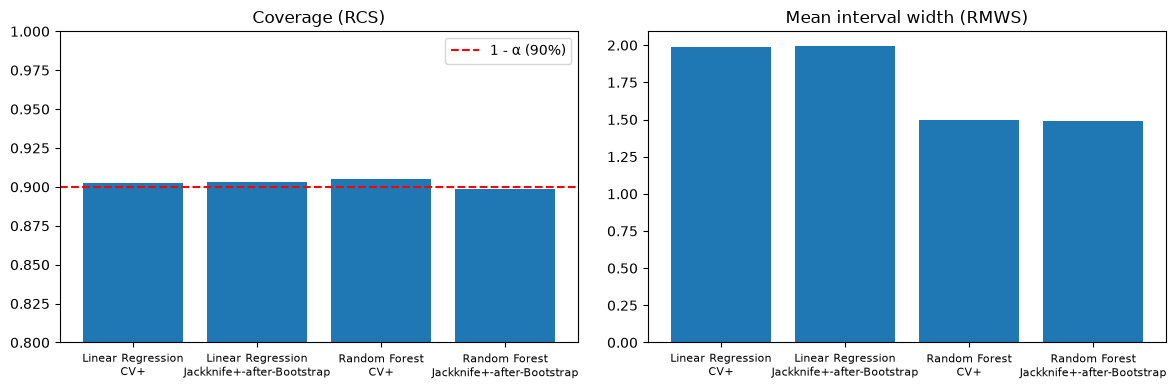

In [8]:
labels = results_df["Model"] + "\n" + results_df["Method"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(labels, results_df["RCS"])
axes[0].axhline(1 - alpha, color="red", linestyle="--", label="1 - α (90%)")
axes[0].set_ylim(0.8, 1)
axes[0].set_title("Coverage (RCS)")
axes[0].legend()

axes[1].bar(labels, results_df["RMWS"])
axes[1].set_title("Mean interval width (RMWS)")

for ax in axes:
    ax.tick_params(axis="x", labelsize=8)

plt.tight_layout()
plt.savefig("cp_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [9]:
alpha = 0.10
methods = {"CV+": cv_plus, "Jackknife+-after-Bootstrap": jackknife_plus_after_bootstrap}

results = []
intervals = {}                                                  
for model_name, model in models.items():
    for method_name, method in methods.items():
        lower, upper = method(model, X_rest, y_rest, X_test, alpha=alpha)
        intervals[(model_name, method_name)] = (lower, upper)   
        rcs, rmws = evaluate_cp(y_test, lower, upper)
        results.append({"Model": model_name, "Method": method_name,
                        "Target": 1 - alpha, "RCS": rcs, "RMWS": rmws})
        print(f"{model_name} / {method_name} : RCS = {rcs:.2%}, RMWS = {rmws:.4f}")

results_df = pd.DataFrame(results)
results_df.round(4)

Linear Regression / CV+ : RCS = 90.27%, RMWS = 1.9902
Linear Regression / Jackknife+-after-Bootstrap : RCS = 90.32%, RMWS = 1.9936
Random Forest / CV+ : RCS = 90.50%, RMWS = 1.4998
Random Forest / Jackknife+-after-Bootstrap : RCS = 89.85%, RMWS = 1.4904


,Model,Method,Target,RCS,RMWS
0,Linear Regression,CV+,0.9,0.9027,1.9902
1,Linear Regression,Jackknife+-after-Bootstrap,0.9,0.9032,1.9936
2,Random Forest,CV+,0.9,0.9050,1.4998
3,Random Forest,Jackknife+-after-Bootstrap,0.9,0.8985,1.4904


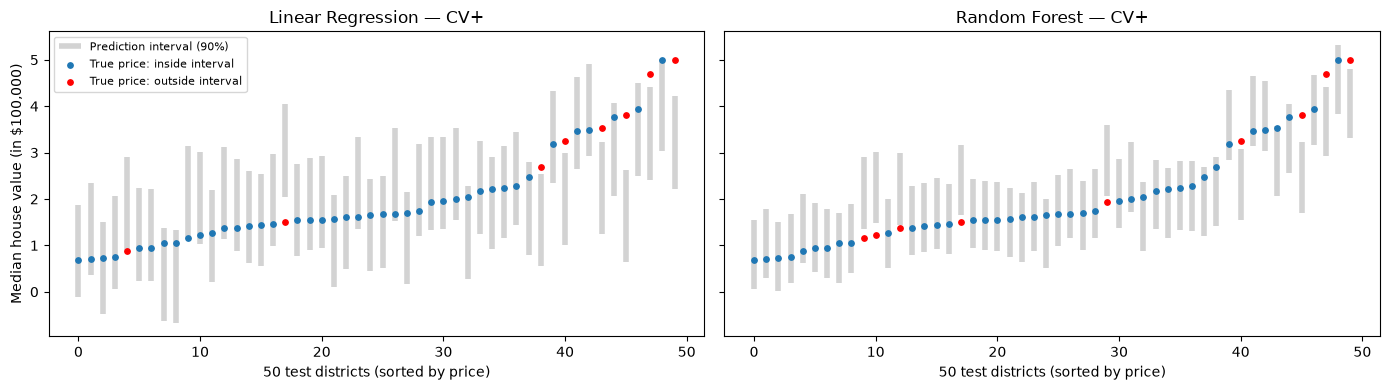

In [10]:
rng = np.random.default_rng(1)
idx = rng.choice(len(y_test), size=50, replace=False)
idx = idx[np.argsort(y_test[idx])]
x = np.arange(len(idx))

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, model_name in zip(axes, ["Linear Regression", "Random Forest"]):
    lower, upper = intervals[(model_name, "CV+")]
    inside = (y_test[idx] >= lower[idx]) & (y_test[idx] <= upper[idx])
    ax.vlines(x, lower[idx], upper[idx], color="lightgray", linewidth=4, label="Prediction interval (90%)")
    ax.scatter(x[inside], y_test[idx][inside], color="tab:blue", s=15, zorder=3, label="True price: inside interval")
    ax.scatter(x[~inside], y_test[idx][~inside], color="red", s=15, zorder=3, label="True price: outside interval")
    ax.set_title(f"{model_name} — CV+")
    ax.set_xlabel("50 test districts (sorted by price)")
axes[0].set_ylabel("Median house value (in $100,000)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("cp_intervals.png", dpi=300, bbox_inches="tight")
plt.show()

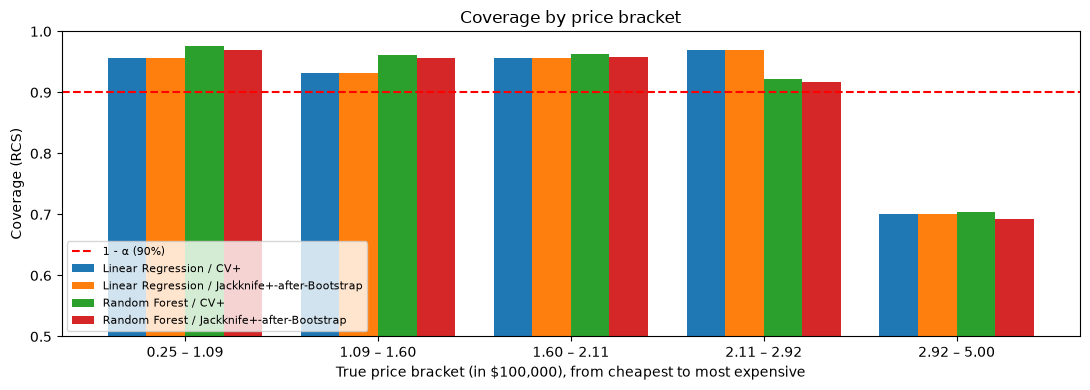

In [11]:
bins = pd.qcut(y_test, q=5)
bin_labels = [f"{b.left:.2f} – {b.right:.2f}" for b in bins.categories]
x = np.arange(len(bin_labels))
width = 0.2

fig, ax = plt.subplots(figsize=(11, 4))
for i, ((model_name, method_name), (lower, upper)) in enumerate(intervals.items()):
    covered = (y_test >= lower) & (y_test <= upper)
    cov_by_bin = pd.Series(covered).groupby(bins.codes).mean()
    ax.bar(x + (i - 1.5) * width, cov_by_bin.values, width, label=f"{model_name} / {method_name}")

ax.axhline(1 - alpha, color="red", linestyle="--", label="1 - α (90%)")
ax.set_xticks(x)
ax.set_xticklabels(bin_labels)
ax.set_xlabel("True price bracket (in $100,000), from cheapest to most expensive")
ax.set_ylabel("Coverage (RCS)")
ax.set_ylim(0.5, 1)
ax.set_title("Coverage by price bracket")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig("cp_coverage_by_price.png", dpi=300, bbox_inches="tight")
plt.show()